In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: []


In [3]:
!pip -q install tensorflow-datasets

In [5]:
!pip install -q importlib_resources tensorflow-datasets

In [6]:
import tensorflow_datasets as tfds

(train_ds, val_ds, test_ds), info = tfds.load(
    'food101',
    split=['train[:5%]', 'train[5%:6%]', 'validation[:2%]'],
    as_supervised=True,
    with_info=True
)

class_names = info.features['label'].names

print("Number of classes:", len(class_names))
print("Sample classes:", class_names[:10])

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.VWWVC0_2.0.0/food101-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.VWWVC0_2.0.0/food101-validation.tfrecord-[0-9][0-9][0-9…

Dataset food101 downloaded and prepared to /root/tensorflow_datasets/food101/2.0.0. Subsequent calls will reuse this data.
Number of classes: 101
Sample classes: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']


In [7]:
# Step 2: Prepare the dataset

IMG_SIZE = 160
BATCH_SIZE = 32

def preprocess_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = preprocess_input(image)
    return image, label

train_ds = train_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = test_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Dataset preprocessing completed successfully!")
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Dataset preprocessing completed successfully!
Image size: 160 x 160
Batch size: 32


In [8]:
# Step 3: Build the Food Recognition Model

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load the pretrained model
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Build our classification model
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation="softmax")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 160, 160, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 101)            │       129,381 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,387,365 (9.11 MB)

 Trainable params: 129,381 (505.39 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
# Step 4: Train the Food Recognition Model

EPOCHS = 5

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.1426 - loss: 4.0054 - val_accuracy: 0.2906 - val_loss: 3.0106
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.4195 - loss: 2.3752 - val_accuracy: 0.3540 - val_loss: 2.6221
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 132s 945ms/step - accuracy: 0.5359 - loss: 1.8467 - val_accuracy: 0.3791 - val_loss: 2.5091
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 137s 904ms/step - accuracy: 0.6180 - loss: 1.5178 - val_accuracy: 0.4016 - val_loss: 2.4410
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 107s 883ms/step - accuracy: 0.6674 - loss: 1.2978 - val_accuracy: 0.4003 - val_loss: 2.4131


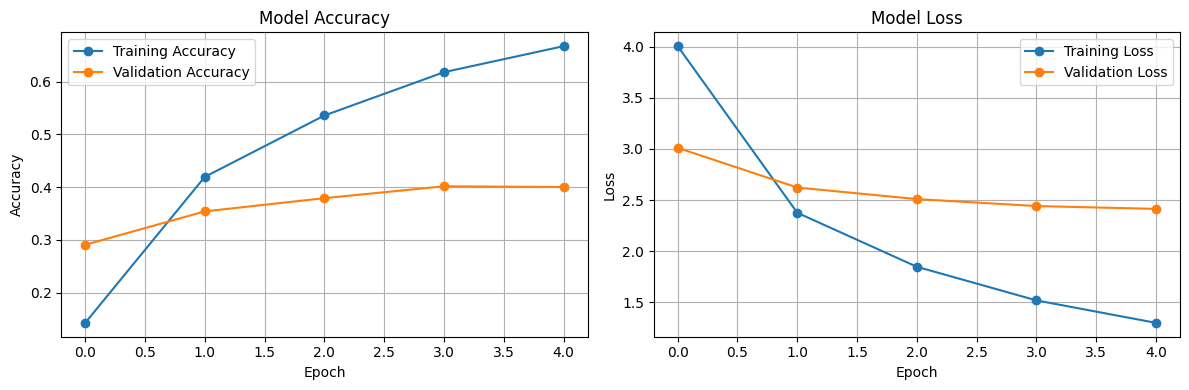

In [10]:
# Step 5: Plot Accuracy and Loss

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], marker='o', label='Training Accuracy')
plt.plot(history.history['val_accuracy'], marker='o', label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], marker='o', label='Training Loss')
plt.plot(history.history['val_loss'], marker='o', label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [11]:
# Step 6: Evaluate the Model

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 579ms/step - accuracy: 0.4455 - loss: 2.1841
Test Loss: 2.1841
Test Accuracy: 44.55%


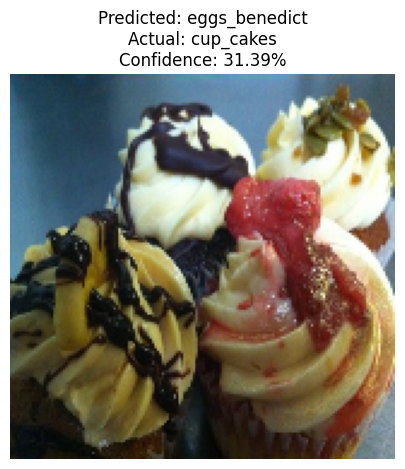

In [12]:
# Step 7: Predict a Food Category

for images, labels in test_ds.take(1):
    sample_image = images[0]
    actual_label = int(labels[0].numpy())

    probabilities = model.predict(
        tf.expand_dims(sample_image, axis=0),
        verbose=0
    )[0]

    predicted_label = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_label])

    # Convert the image back for display
    display_image = (sample_image.numpy() + 1) / 2
    display_image = np.clip(display_image, 0, 1)

    plt.figure(figsize=(6, 5))
    plt.imshow(display_image)
    plt.axis("off")

    plt.title(
        f"Predicted: {class_names[predicted_label]}\n"
        f"Actual: {class_names[actual_label]}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )

    plt.show()

In [13]:
# Step 8: Food Calorie Estimation

calorie_data = {
    "pizza": {"serving": "1 medium slice", "calories": 285},
    "hamburger": {"serving": "1 burger", "calories": 250},
    "hot_dog": {"serving": "1 hot dog", "calories": 290},
    "french_fries": {"serving": "100 g", "calories": 312},
    "ice_cream": {"serving": "100 g", "calories": 207},
    "caesar_salad": {"serving": "1 serving", "calories": 180},
    "sushi": {"serving": "100 g", "calories": 150},
    "fried_rice": {"serving": "1 cup", "calories": 250},
    "omelette": {"serving": "1 omelette", "calories": 180},
    "spaghetti_bolognese": {"serving": "1 serving", "calories": 350}
}

predicted_food = class_names[predicted_label]

print("Predicted Food:", predicted_food.replace("_", " ").title())

if predicted_food in calorie_data:
    info = calorie_data[predicted_food]
    print("Serving Size:", info["serving"])
    print("Estimated Calories:", info["calories"], "kcal")
else:
    print("Calorie information is not available for this food yet.")
    print("Add a verified nutritional value for this category.")

Predicted Food: Eggs Benedict
Calorie information is not available for this food yet.
Add a verified nutritional value for this category.


In [14]:
model.save("food_recognition_model.keras")

print("Model saved successfully!")

Model saved successfully!
